In [ ]:
READ ME

# Análisis de uso de clientes ConnectaTel

## Descripción del proyecto

ConnectaTel es una empresa de telecomunicaciones en Latinoamérica. Este proyecto analiza el comportamiento de sus clientes con información registrada hasta 2024, con el fin de:

- identificar patrones de uso (llamadas y mensajes),
- detectar comportamientos atípicos (outliers),
- reconocer segmentos de clientes con necesidades distintas,
- y proponer mejoras en la oferta comercial y en la experiencia del usuario.

## Datasets utilizados

| Archivo | Contenido |
|---|---|
| `plans.csv` | Planes actuales: precio, minutos incluidos, GB incluidos y costo por extra (2 planes: Basico y Premium). |
| `users_latam.csv` | Información de 4,000 clientes: identificador, nombre, edad, ciudad, fecha de registro, plan contratado y fecha de baja (`churn_date`). |
| `usage.csv` | Detalle del uso real (40,000 registros): tipo de registro (`call` o `text`), duración de las llamadas (`duration`) y longitud de los mensajes (`length`). |

## Herramientas

- Python 3
- pandas (manipulación y agregación de datos)
- numpy (segmentación con condiciones)
- seaborn y matplotlib (visualización)

## Etapas del análisis

1. **Carga y exploración:** lectura de los tres datasets, `.head()`, `.shape` e `.info()`.
2. **Calidad de datos:** revisión de nulos, sentinels (valores de relleno) y fechas fuera de rango.
3. **Limpieza:** sentinels convertidos a valores válidos o nulos, fechas imposibles marcadas como nulas, `churn_date` convertida a fecha y nulos de `duration` y `length` conservados tras confirmar que dependen de `type` (MAR).
4. **Resumen por usuario:** agregación de `usage` por `user_id` (cantidad de mensajes, llamadas y minutos) y unión con `users`.
5. **Visualización de distribuciones:** histogramas por plan de edad, mensajes, llamadas y minutos.
6. **Detección de outliers:** boxplots y método IQR.
7. **Segmentación:** grupos por nivel de uso (`grupo_uso`) y por edad (`grupo_edad`).
8. **Resumen ejecutivo** con conclusiones y recomendaciones.

## Cómo ejecutar el notebook

### Opción 1: Google Colab

1. Abre el notebook en Colab: [enlace al notebook].
2. Sube los tres archivos CSV desde el panel lateral de archivos (ícono de carpeta, luego "Subir").
3. Ajusta las rutas de lectura. En el notebook original los archivos se leen desde `/datasets/`; en Colab quedan en `/content/`:

   ```python
   plans = pd.read_csv('/content/plans.csv')
   users = pd.read_csv('/content/users_latam.csv')
   usage = pd.read_csv('/content/usage.csv')
   ```

4. Ejecuta las celdas en orden desde "Entorno de ejecución" y luego "Ejecutar todo".

### Opción 2: Jupyter local

1. Instala las dependencias:

   ```bash
   pip install pandas numpy seaborn matplotlib jupyter
   ```

2. Coloca los CSV en una carpeta `datasets/` junto al notebook y ajusta las rutas de lectura (`'datasets/plans.csv'`, etc.).
3. Inicia Jupyter con `jupyter notebook` y abre `[nombre_del_notebook].ipynb`.

## Guía breve de reproducción

- Ejecuta las celdas **en orden**: varias dependen de columnas creadas antes (por ejemplo, `cant_mensajes`, `cant_llamadas` y `cant_minutos_llamada` se crean en el resumen por usuario y se usan en los gráficos y la segmentación).
- Si reinicias el kernel, vuelve a ejecutar desde la primera celda para recuperar los DataFrames y las columnas nuevas.
- Si aparece `FileNotFoundError`, revisa la ruta de los CSV.
- Si aparece `NameError`, revisa que hayas ejecutado antes la celda donde se define esa variable o librería.

## Hallazgos principales

**Calidad de los datos**

- `city`: 565 filas (14.1%) sin ciudad válida (469 nulos y 96 con el valor `?`).
- `age`: valor centinela `-999`, reemplazado por la mediana.
- `reg_date`: 40 registros (1.0%) con la misma fecha imposible, `2026-05-10`, lo que apunta a un valor por defecto del sistema.
- `churn_date`: guardada como marca de tiempo numérica y convertida a fecha.
- `duration` y `length`: los nulos se explican por el tipo de registro (llamada o mensaje).

**Segmentos de clientes**

| Nivel de uso | Usuarios | % |
|---|---|---|
| Uso medio | 2,943 | 73.6% |
| Bajo uso | 778 | 19.4% |
| Alto uso | 279 | 7.0% |

| Grupo de edad | Usuarios | % |
|---|---|---|
| Adulto (30 a 59) | 2,018 | 50.4% |
| Adulto Mayor (60 o más) | 1,222 | 30.6% |
| Joven (menos de 30) | 760 | 19.0% |

**Patrones de uso**

- El consumo es bajo y homogéneo: la mediana es de 5 mensajes, 4 llamadas y unos 20 minutos por usuario.
- La edad y el plan no determinan el nivel de uso: los tres grupos de edad y los dos planes tienen una forma de consumo casi idéntica.
- Los outliers aparecen solo del lado derecho. En minutos, el máximo es 155.7 frente a un límite IQR de 61.9, con un grupo aislado entre 130 y 155 minutos. Se conservaron por ser valores plausibles y relevantes para el negocio.

**Recomendaciones**

- Revisar la diferenciación entre los planes Basico y Premium, ya que no se distinguen por el consumo.
- Crear un plan de entrada para el grupo de bajo uso y un plan o complemento para el de alto uso.
- Enfocar la retención en el nivel de uso y no en la edad.
- Mejorar la validación de datos en el origen (fechas, valores de relleno y formato de `churn_date`).
- Cruzar el uso con `churn_date` y con ingresos por cliente para confirmar qué segmentos son los más valiosos.

SyntaxError: invalid syntax (2129830213.py, line 1)

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos

plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
# mostrar las primeras 5 filas de plans
print("Plans")
print(plans.head())

Plans
  plan_name  messages_included  gb_per_month  minutes_included  \
0    Basico                100             5               100   
1   Premium                500            20               600   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute  
0               12         1.2             0.08            0.10  
1               25         1.0             0.05            0.07  


In [ ]:
# mostrar las primeras 5 filas de users
print("\nUsers")
print(users.head())


Users
   user_id first_name last_name  age      city                       reg_date  \
0    10000     Carlos    Garcia   38  Medellín  2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres   53         ?  2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez   57      CDMX  2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez   69    Bogotá  2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres   63       GDL  2022-01-02 02:17:11.657914478   

      plan churn_date  
0   Basico        NaN  
1   Basico        NaN  
2   Basico        NaN  
3  Premium        NaN  
4   Basico        NaN  


In [ ]:
# mostrar las primeras 5 filas de usage
print("\nUsage")
print(usage.head())


Usage
   id  user_id  type                           date  duration  length
0   1    10332  call  2024-01-01 00:00:00.000000000      0.09     NaN
1   2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2   3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
3   4    10682  call  2024-01-01 00:19:32.909322733      1.53     NaN
4   5    12742  call  2024-01-01 00:26:03.879096977      4.84     NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
# inspección de plans con .info()
print("\nInfo de plans")
plans.info()


Info de plans
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
# inspección de users con .info()
print("\nInfo de users")
users.info()


Info de users
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
# inspección de usage con .info()
print("\nInfo de usage")
usage.info()


Info de usage
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# Cantidad de nulos por columna
print("Nulos en users")
print(users.isna().sum())

print("\nNulos en usage")
print(usage.isna().sum())

# Proporción de nulos por columna
print("\nProporción de nulos en users")
print(users.isna().mean())

Nulos en users
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Nulos en usage
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de nulos en users
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print("\nProporción de nulos en usage")
print(usage.isna().mean())


Proporción de nulos en usage
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**

- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.



El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
print("Resumen numérico de users")
print(users[['age']].describe())

Resumen numérico de users
               age
count  4000.000000
mean     33.739750
std     123.232257
min    -999.000000
25%      32.000000
50%      47.000000
75%      63.000000
max      79.000000




- La columna `user_id` tiene valores que van de [min] a [max], con [N] registros. Es un identificador, así que su media y desviación no tienen interpretación.
- La columna `age`va de [min] a [max] años, con media de [media] y mediana de [50%].



In [ ]:
# explorar columnas numéricas de usage
print("\nResumen numérico de usage")
print(usage.describe())


Resumen numérico de usage
                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000



- Las columnas `id` y `user_id`va de 1 a 40,000 con 40,000 registros y una media de 20,000.5, justo la mitad del rango, lo que indica una secuencia consecutiva sin huecos.


In [ ]:
# explorar columnas categóricas de users
print("\nValores únicos en users")
for col in ['city', 'plan']:
    print(f"\n{col}")
    print(users[col].value_counts(dropna=False))



Valores únicos en users

city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

plan
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` tiene 6 ciudades válidas (Bogotá, CDMX, Medellín, GDL, Cali y MTY), con Bogotá (808) y CDMX (730) como las más frecuentes. Se encontraron 469 valores nulos (11.7%) y 96 registros con el valor ? (2.4%), que es un sentinel porque es un símbolo de relleno que no corresponde a ninguna ciudad. En total, 565 registros (14.1%) no tienen una ciudad válida. No se observan variantes de escritura de una misma ciudad.
  
- La columna `plan` tiene solo dos valores, Basico (2,595 usuarios, 64.9%) y Premium (1,405, 35.1%). No tiene nulos ni valores inválidos, y los dos planes coinciden con los 2 renglones del dataset plans.

In [ ]:
# explorar columna categórica de usage
print("\nValores únicos en usage")
print(usage['type'].value_counts(dropna=False))


Valores únicos en usage
text    22092
call    17908
Name: type, dtype: int64


- La columna `type` tiene solo dos valores, text (22,092 registros, 55.2%) y call (17,908, 44.8%)



---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?


city (users): contiene el valor ? en 96 registros (2.4%), un sentinel que no corresponde a ninguna ciudad. Además tiene 469 nulos (11.7%). En total, 565 registros (14.1%) no tienen una ciudad válida.

duration (usage): el mínimo es 0 y el máximo es exactamente 120, muy alejado del percentil 75 (6.99). El 0 puede ser una llamada perdida o un sentinel, y el 120 podría ser un tope del sistema o un valor de relleno.

usage: el mínimo es 0 (posibles mensajes vacíos) y el máximo es 1490, muy por encima del percentil 75 (64) y de lo normal en un mensaje de texto. Es un probable sentinel o error de captura.

Inconsistencia entre type, duration y length: hay 17,908 llamadas pero 17,924 valores en duration (al menos 16 de más), y 22,092 mensajes pero 22,104 valores en length (al menos 12 de más). Algunos registros tienen llena una columna que no corresponde a su tipo.
Sin problemas: id, user_id, plan y type no muestran nulos, valores fuera de rango ni variantes de escritura.


¿Qué acción tomaría?

* city: reemplazar '?' por nulo y dejar los 565 nulos sin imputar. Es el 14,1% de los datos, y asignar una ciudad inventada distorsionaría el análisis por ciudad.
* duration: contar cuántas filas tienen valores 0 y 120. Si el 120 se repite en muchas filas, tratarlo como un sentinel y convertirlo en nulo. Los 0 se conservarían solo si representan llamadas perdidas reales; si no, se convierten en nulos.
* length: contar las filas con 0 y con valores muy altos. Si el 1490 es un caso aislado, tratarlo como outlier o error de captura y convertirlo en nulo; los mensajes de longitud 0 se revisan igual que los de duración 0.
* type vs. duration/length: cuantificar los registros inconsistentes. Como son pocos (unos 28), se puede poner en nulo la columna que no corresponde (length en las llamadas, duration en los mensajes) o excluir esos registros.



### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')


In [ ]:
# Convertir a fecha la columna `date` de usage
print(users['reg_date'].dtype)
print("Fechas no válidas (NaT):", users['reg_date'].isna().sum())

datetime64[ns]
Fechas no válidas (NaT): 0


In [ ]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts().sort_index())


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, los registros se distribuyen de forma muy pareja entre 2022 (1,314), 2023 (1,316) y 2024 (1,330), con alrededor de 1,300 altas por año. Además, aparecen 40 registros (1.0%) con año 2026, que es una fecha imposible: los datos llegan hasta 2024, así que son errores de captura. La conversión con errors='coerce' no generó fechas nulas, por lo que no había valores con formato inválido, solo años fuera de rango.

In [ ]:
# Revisar los años presentes en `date` de usage
print(users[users['reg_date'].dt.year > 2024])


      user_id first_name last_name  age      city   reg_date     plan  \
40      10040        Ana    Garcia   59  Medellín 2026-05-10   Basico   
56      10056       Luis    Garcia   29      CDMX 2026-05-10   Basico   
60      10060     Carlos    Torres   45      CDMX 2026-05-10   Basico   
70      10070    Mariana     Gomez   50      CDMX 2026-05-10  Premium   
248     10248      Sofia    Garcia   20  Medellín 2026-05-10  Premium   
320     10320      Sofia    Garcia   74       GDL 2026-05-10  Premium   
326     10326    Mariana    Torres   51  Medellín 2026-05-10  Premium   
505     10505       Luis    Garcia   75      CDMX 2026-05-10   Basico   
527     10527     Carlos    Torres   71       MTY 2026-05-10   Basico   
646     10646       Luis   Ramirez   50      CDMX 2026-05-10  Premium   
885     10885        Ana    Torres   73    Bogotá 2026-05-10   Basico   
914     10914    Mariana    Garcia   25       GDL 2026-05-10   Basico   
948     10948      Sofia    Torres   30       MTY 2

En `date`, os registros se distribuyen de forma pareja entre 2022, 2023 y 2024 (alrededor de 1,300 por año), pero 40 usuarios (1.0%) aparecen con la fecha 2026-05-10. Es una fecha imposible, porque los datos llegan hasta 2024, y es idéntica en todos los casos, lo que indica un valor por defecto del sistema y no un error de captura individual. Además, varios de estos usuarios tienen una baja registrada en 2024, anterior a su supuesta fecha de registro, lo que confirma que la fecha es inválida. Se convertirán en nulo, sin imputar una fecha inventada, y se conservarán los registros porque el resto de sus datos es utilizable. Basaremos el análisis en las fechas de 2022 a 2024.


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles?

Sí. En reg_date los registros se reparten de forma pareja entre 2022 (1,314), 2023 (1,316) y 2024 (1,330), pero aparecen 40 usuarios (1.0%) con año 2026, que no puede ser real porque los datos llegan hasta 2024. Los 40 tienen exactamente la misma fecha, 2026-05-10, lo que indica un valor por defecto del sistema (un sentinel) y no errores de captura individuales. Hay una contradicción que lo confirma: varios de estos usuarios tienen churn_date en 2024, es decir, una baja anterior a su supuesto registro. No aparecen años muy antiguos ni negativos, y la conversión con errors='coerce' no generó fechas nulas, así que no había valores con formato inválido.
  
- ¿Qué harías con ellas?

reg_date de 2026: convertir esas 40 fechas en nulo (NaT) y no imputar una fecha inventada. Es solo el 1% de los usuarios, y asignar una fecha distorsionaría el análisis de antigüedad. Los registros se conservan, porque el resto de sus datos (plan, ciudad, edad) sigue siendo utilizable.
churn_date: convertirla a fecha, porque venía como marca de tiempo numérica en nanosegundos (valores como 1,72187E+18). Sus nulos se interpretan como clientes que siguen activos.
Análisis posterior: basarlo en las fechas de 2022 a 2024.


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users.loc[users['city'] == '?', 'city'] = pd.NA

# Verificar cambios


In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios


In [ ]:

print(users['reg_date'].isna().sum())  # debería dar 40
print(users['reg_date'].dt.year.value_counts().sort_index())

40
2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage.groupby('type')[['duration', 'length']].apply(lambda g: g.isna().sum()))


      duration  length
type                  
call         0   17896
text     22076       0


In [ ]:
# Verificación MAR en usage (Missing At Random) para length
print(usage.groupby('type')[['duration', 'length']].apply(lambda g: g.isna().mean()))


      duration   length
type                   
call  0.000000  0.99933
text  0.999276  0.00000


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Los nulos de duration y length dependen de la columna type: duration solo se registra en las llamadas y length solo en los mensajes, por lo que en cada caso la columna es nula en [X]% de los registros del otro tipo y casi nunca en los del tipo que le corresponde. Como la ausencia se explica por una variable observada, los nulos son MAR. Se dejan como nulos, sin imputar: rellenarlos con 0, la media o la mediana inventaría llamadas con longitud de mensaje o mensajes con duración, y distorsionaría el análisis. Al calcular estadísticas de cada columna, pandas ignora los nulos, y conviene filtrar por type antes de analizar cada una.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares

usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg.columns = ['user_id', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios

users = users.merge(usage_agg, on='user_id', how='left')

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
columnas_num = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
print(users[columnas_num].describe())

               age  cant_mensajes  cant_llamadas  cant_minutos_llamada
count  4000.000000    3999.000000    3999.000000           3999.000000
mean     48.136000       5.524381       4.478120             23.317054
std      17.689919       2.358416       2.144238             18.168095
min      18.000000       0.000000       0.000000              0.000000
25%      33.000000       4.000000       3.000000             11.120000
50%      48.000000       5.000000       4.000000             19.780000
75%      63.000000       7.000000       6.000000             31.415000
max      79.000000      17.000000      15.000000            155.690000


In [ ]:
# Distribución porcentual del tipo de plan
print((users['plan'].value_counts(normalize=True) * 100).round(2))

Basico     64.88
Premium    35.12
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

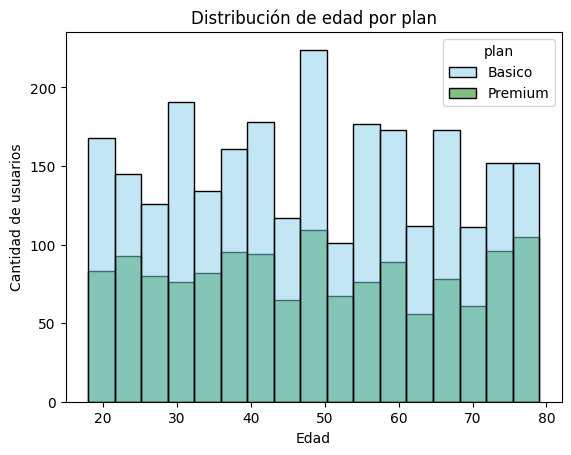

In [ ]:
# Histograma para visualizar la edad (age)

sns.histplot(data=users, x='age', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de edad por plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
La distribución de edad es aproximadamente uniforme, sin sesgo marcado: los usuarios van de unos 18 a 79 años y las barras tienen alturas parecidas, sin una cola larga hacia ningún lado. No se ve una forma de campana, y la ausencia de valores negativos confirma que el sentinel -999 ya fue corregido. Ambos planes siguen la misma forma, y Basico queda por encima en casi todos los rangos porque tiene más usuarios (64.9% frente a 35.1%). La proporción de Premium respecto a Basico se mantiene más o menos estable entre edades, así que no existe un patrón claro de edad según el plan.

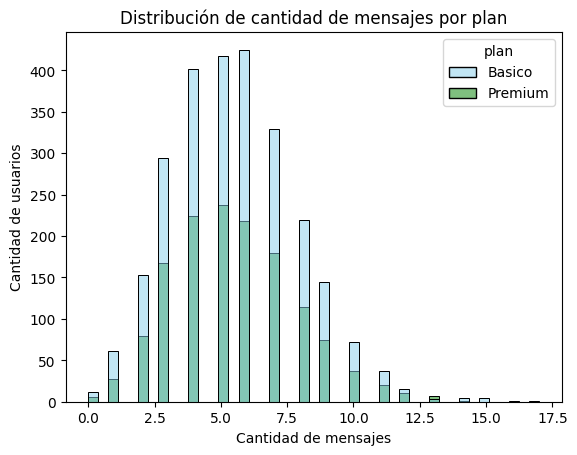

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=users, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de cantidad de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights:

La distribución es ligeramente sesgada a la derecha. La mayoría de los usuarios envía entre 3 y 7 mensajes, con el pico en 4 a 6 (unos 420 usuarios de Basico y unos 237 de Premium en el valor más alto). Después hay una cola corta hacia valores altos, que llega hasta unos 17 mensajes, pero con muy pocos usuarios. En la parte baja hay muy pocos usuarios con 0 o 1 mensaje. Ambos planes tienen la misma forma y el mismo centro, y Premium mantiene una proporción más o menos constante frente a Basico en todo el rango (cercana al 35% del total de usuarios), por lo que no existe un patrón claro por plan: los usuarios de ambos planes envían una cantidad parecida de mensajes. La mayor altura de Basico se debe a que tiene más usuarios.

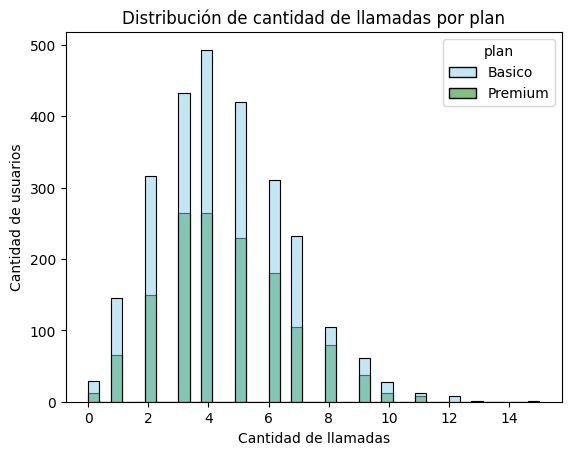

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=users, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de cantidad de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights:

La distribución es ligeramente sesgada a la derecha. La mayoría de los usuarios hace entre 2 y 6 llamadas, con el pico en 4 (unos 490 usuarios de Basico y unos 265 de Premium), y una cola corta que llega a unas 15 llamadas con muy pocos usuarios. Hay poca gente con 0 o 1 llamada. Ambos planes tienen la misma forma y el mismo centro: la barra de Premium se mantiene en una proporción parecida frente a Basico en todo el rango. La mayor altura de Basico se debe a que tiene más usuarios, así que no existe un patrón claro por plan: los usuarios de ambos planes hacen una cantidad similar de llamadas.

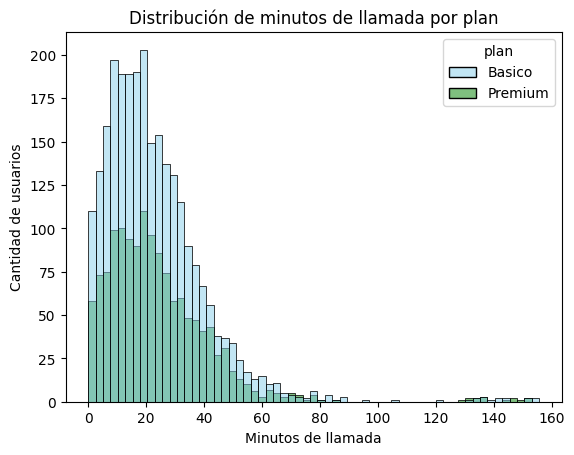

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=users, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de minutos de llamada por plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:

La distribución está claramente sesgada a la derecha. La mayor concentración está entre 5 y 25 minutos, con el pico cerca de 20, y a partir de ahí desciende de forma gradual hasta unos 60 a 80 minutos. Los usuarios de Basico y Premium siguen la misma forma, de modo que tampoco hay una diferencia clara en el consumo de minutos según el plan. Lo más llamativo es un pequeño grupo aislado entre 130 y 155 minutos, separado del resto por un hueco amplio. Aparece en ambos planes, y son pocos usuarios, pero con un consumo varias veces mayor al típico: son los candidatos a outliers que analizaremos en el siguiente paso.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

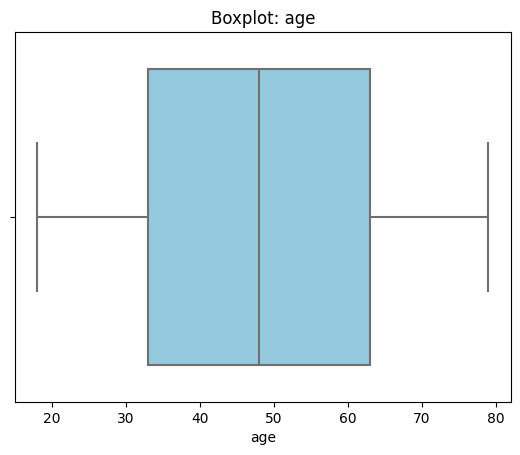

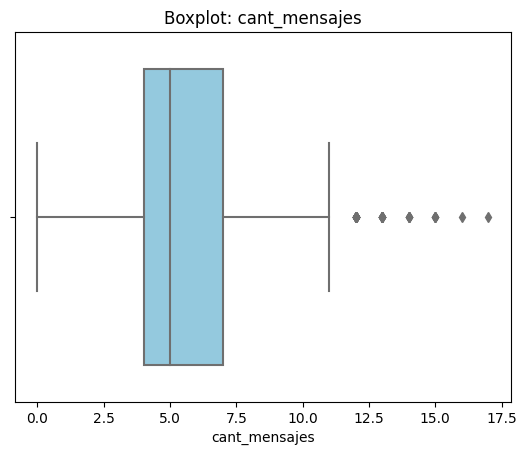

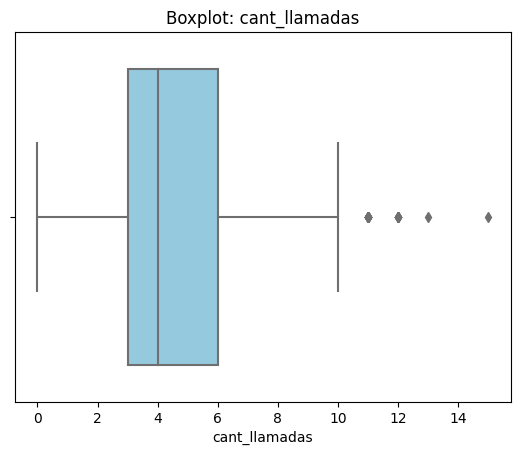

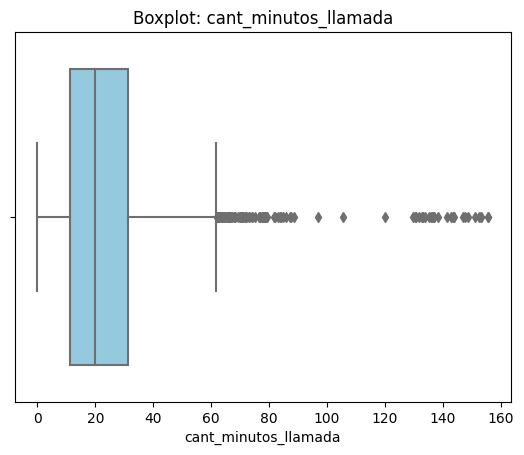

In [ ]:

# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=users[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()


💡Insights:
- Age: no presenta outliers. Los bigotes llegan de unos 18 a 79 años sin ningún punto suelto. La caja va de unos 33 a 63 años, con la mediana cerca de 48, y la distribución es bastante simétrica. Confirma que la limpieza del -999 funcionó, porque no queda ningún valor imposible.
  
- cant_mensajes: presenta outliers solo del lado derecho. El bigote llega a 11 y los puntos sueltos aparecen entre 12 y 17 mensajes. La caja va de 4 a 7, con la mediana en 5. No hay outliers por abajo: el bigote inferior llega a 0, que es el mínimo posible. Los valores extremos son pocos y solo superan el límite (11.5) por unos mensajes.

  
- cant_llamadas: presenta outliers solo del lado derecho. El bigote llega a 10 y hay puntos sueltos en 11, 12, 13 y 15 llamadas. La caja va de 3 a 6, con la mediana en 4. Son pocos usuarios y el exceso sobre el límite (10.5) es moderado.

  
- cant_minutos_llamada: presenta outliers solo del lado derecho, y son los más marcados. El bigote llega a unos 62 minutos (el límite es 61.86) y hay una nube densa de puntos entre 62 y 90 minutos. Después aparecen puntos aislados cerca de 97, 105 y 120, y un segundo grupo entre 130 y 155 minutos, separado del resto por un hueco amplio. La caja va de unos 11 a 31 minutos, con la mediana cerca de 20.


In [ ]:

# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = users[col].quantile(0.25)
    Q3 = users[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR

    print(f"{col}")
    print("  Límite superior:", limite_superior)
    print("  Outliers por encima:", (users[col] > limite_superior).sum())
    print()


cant_mensajes
  Límite superior: 11.5
  Outliers por encima: 46

cant_llamadas
  Límite superior: 10.5
  Outliers por encima: 30

cant_minutos_llamada
  Límite superior: 61.8575
  Outliers por encima: 109



In [ ]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
users[columnas_limites].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights:
- cant_mensajes: mantener los outliers. El límite superior es 11.5 y el máximo es 17, así que los valores extremos solo superan el límite por unos pocos mensajes. Enviar 12 a 17 mensajes es un uso perfectamente posible, y son usuarios de uso algo más intenso, no errores. Además, la media (5.52) y la mediana (5) casi coinciden, por lo que estos valores casi no distorsionan el resumen.
  
- cant_llamadas: mantener los outliers. El límite superior es 10.5 y el máximo es 15, un exceso moderado. Hacer entre 11 y 15 llamadas es un comportamiento plausible, y la media (4.48) está muy cerca de la mediana (4). Eliminarlos haría perder justo a los usuarios más activos.

  
- cant_minutos_llamada: mantener los outliers, pero revisarlos. Aquí el máximo (155.69) es unas 2.5 veces el límite superior (61.86), y la media (23.3) queda por encima de la mediana (19.8), lo que confirma el sesgo a la derecha. Son pocos usuarios, y 155 minutos de llamadas es un consumo posible. Además, un cliente de uso intensivo es relevante para diseñar planes y estrategias de retención. Se conservan, y se usa la mediana en lugar de la media al resumir el consumo. Los trataría como error solo si se demuestra que son imposibles o que se repite un valor de relleno, algo que no se ve en el describe().

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
import numpy as np

# Crear columna grupo_uso
condiciones = [
    (users['cant_llamadas'] < 5) & (users['cant_mensajes'] < 5),
    (users['cant_llamadas'] < 10) & (users['cant_mensajes'] < 10)
]
categorias = ['Bajo uso', 'Uso medio']

users['grupo_uso'] = np.select(condiciones, categorias, default='Alto uso')

In [ ]:
# verificar cambios
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
condiciones = [
    users['age'] < 30,
    users['age'] < 60
]
categorias = ['Joven', 'Adulto']

users['grupo_edad'] = np.select(condiciones, categorias, default='Adulto Mayor')

# verificar cambios
print(users['grupo_edad'].value_counts())

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


In [ ]:
# verificar cambios
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

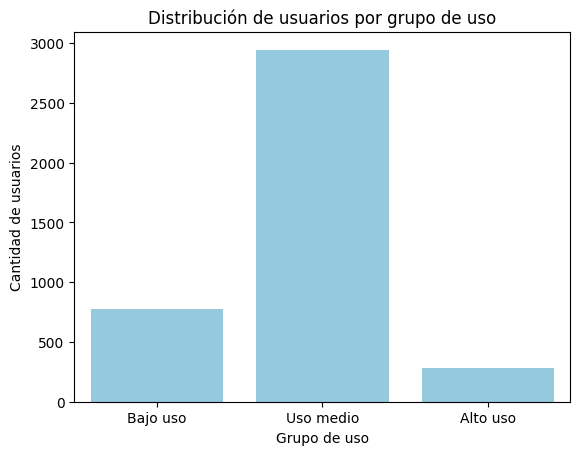

In [ ]:

# Visualización de los segmentos por uso

sns.countplot(data=users, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()


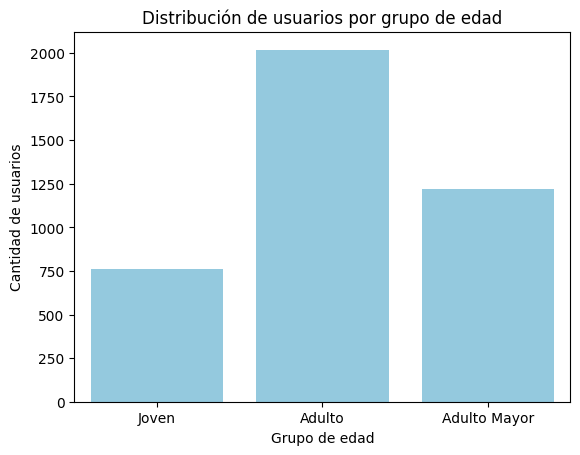

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=users, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], color='skyblue')
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


---

## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

  Columna	Problema	Magnitud	Acción tomada
city	Nulos y valor de relleno ?	469 nulos (11.7%) + 96 ? (2.4%) = 565 filas (14.1%)	? convertido a nulo; nulos conservados, sin inventar ciudades
age	Sentinel -999	[N] filas ([X]%)	Reemplazado por la mediana
reg_date	Fecha imposible 2026-05-10, idéntica en todos los casos	40 filas (1.0%)	Convertida a nulo
churn_date	Guardada como número (marca de tiempo), no como fecha	Columna completa	Convertida a fecha
duration / length	Nulos estructurales: cada columna aplica solo a un tipo de registro	Nulidad explicada por type (MAR)	Conservados como nulos
type vs duration/length	Registros con ambas columnas llenas	Al menos 28 filas	Marcados para revisión


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?

Se crearon dos segmentaciones sobre los 4,000 usuarios.

Por nivel de uso (grupo_uso):

Uso medio: 2,943 usuarios (73.6%). Es el comportamiento típico: menos de 10 llamadas y menos de 10 mensajes, sin llegar a ser bajo uso.
Bajo uso: 778 usuarios (19.4%). Menos de 5 llamadas y menos de 5 mensajes, por debajo de la mediana del consumo.
Alto uso: 279 usuarios (7.0%). Es el grupo más pequeño, con 10 o más llamadas o mensajes, y coincide con los outliers del lado derecho de los boxplots.

Por edad (grupo_edad):

Adulto (30 a 59 años): 2,018 usuarios (50.4%).
Adulto Mayor (60 años o más): 1,222 usuarios (30.6%).
Joven (menos de 30 años): 760 usuarios (19.0%).

Los tamaños de estos grupos reflejan sobre todo cuántos años abarca cada rango, porque la edad se distribuye de forma casi uniforme entre 18 y 79 años.

- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?

  1. Alto uso: consumen más y es donde hay mayor riesgo de pasarse de los minutos incluidos (con costo extra) o de abandonar si el plan se les queda corto. Son prioridad de retención.
 2. Premium con bajo uso: pagan más pero consumen igual que Basico, lo que los hace vulnerables a la baja si no perciben valor.

- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

Solo hay outliers del lado derecho.

Mensajes: 12 a 17 (límite IQR: 11.5). Llamadas: 11 a 15 (límite: 10.5). Son excesos moderados y valores plausibles.
Minutos: el máximo es 155.7, frente a un límite de 61.9 y una mediana de 19.8. Hay un grupo aislado entre 130 y 155 minutos, separado del resto por un hueco amplio y presente en ambos planes.
Implicación: son pocos usuarios con un consumo varias veces mayor al típico. Se conservaron porque son valores posibles y comercialmente relevantes, y se resumieron con la mediana para que no distorsionen los promedios.


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

1. Revisar la diferenciación entre planes. Premium no se distingue de Basico por el uso. Hay que comparar lo que incluye cada plan en plans.csv con el consumo real: si los minutos incluidos superan con holgura el percentil 75 (31 minutos), el plan está sobredimensionado para casi todos los usuarios.
2. Crear un plan de entrada de bajo costo para el grueso de usuarios con consumo bajo, que hoy paga por capacidad que no usa.
3. Ofrecer un plan o complemento de alto consumo para el segmento de uso extremo (más de 60 minutos), con minutos adicionales a precio fijo en vez de cobro por extra, para reducir el riesgo de abandono.
4. Programa de retención para Alto uso y Premium con bajo uso, con beneficios o migración proactiva de plan según su consumo real.
5. Mejorar la calidad del dato en el origen: validar la fecha de registro (nunca posterior a hoy), prohibir valores de relleno en edad y ciudad, y registrar churn_date con formato de fecha.
6. Próximo análisis: cruzar el uso con churn para confirmar qué segmentos abandonan más, y con ingresos para validar cuáles son realmente los más valiosos.


✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo
Se analizaron 4,000 usuarios y 40,000 registros de uso (llamadas y mensajes) hasta 2024.

⚠️ **Problemas detectados en los datos**

Las 40 fechas de 2026 son idénticas, lo que apunta a un valor por defecto del sistema y no a errores de captura individuales. Además, varios de esos usuarios tienen una baja registrada en 2024, anterior a su supuesto registro.


🔍 **Segmentos por Edad**

La edad se distribuye de forma casi uniforme entre 18 y 79 años, sin outliers, por lo que el tamaño de cada grupo depende sobre todo de cuántos años abarca. El comportamiento es prácticamente igual entre grupos: los tres tienen una mediana de 4 llamadas y 5 mensajes, y entre 19 y 20 minutos de llamada.


📊 **Segmentos por Nivel de Uso**

- Dentro de cada grupo de edad, la composición es casi idéntica: Alto uso va de 6.1% a 7.6%, Bajo uso de 18.0% a 21.0% y Uso medio de 72.6% a 74.3%.
- El plan tampoco marca diferencia: Basico (64.9%) y Premium (35.1%) tienen la misma forma de consumo.
- Uso extremo (outliers): solo aparecen del lado derecho. En mensajes (12 a 17, límite 11.5) y llamadas (11 a 15, límite 10.5) los excesos son moderados. En minutos, el máximo es 155.7 frente a un límite de 61.9 y una mediana de 19.8, con un grupo aislado entre 130 y 155 minutos, separado del resto y presente en ambos planes. Se conservaron por ser valores plausibles y comercialmente relevantes.


➡️ Esto sugiere que ni la edad ni el plan permiten predecir cuánto consume un cliente: casi tres de cada cuatro usuarios tienen un consumo medio y homogéneo. Una segmentación comercial por edad aportaría poco, y el nivel de uso es la variable que realmente distingue a los clientes. Los 279 usuarios de alto uso son el segmento más relevante: son los que tienen más probabilidad de exceder los límites de su plan y de abandonar si este se les queda corto. Que Premium consuma igual que Basico indica que su diferencia de valor no está en el uso, algo que conviene revisar. Esta lectura es una hipótesis, porque aún no cruzamos el uso con ingresos ni con la baja de clientes.


💡 **Recomendaciones**
- Revisar la diferenciación entre planes. Premium no se distingue de Basico por su consumo. Hay que comparar lo que incluye cada plan en plans.csv con el uso real: si los minutos incluidos superan con holgura el percentil 75 (31 minutos), el plan está sobredimensionado para la mayoría.
- Crear un plan de entrada de bajo costo para el 19.4% de usuarios de bajo uso, que hoy paga por capacidad que no aprovecha.
- Ofrecer un plan o complemento de alto consumo para los 279 usuarios de uso alto, con minutos adicionales a precio fijo en lugar de cobro por extra, para reducir el riesgo de abandono.

In [ ]:
# Tamaño de cada segmento
for col in ['grupo_uso', 'grupo_edad']:
    print(users[col].value_counts())
    print((users[col].value_counts(normalize=True) * 100).round(1))
    print()

# Uso mediano por grupo de edad
print(users.groupby('grupo_edad')[['cant_llamadas', 'cant_mensajes', 'cant_minutos_llamada']].median())

# Composición del uso por grupo de edad (porcentaje por fila)
print((pd.crosstab(users['grupo_edad'], users['grupo_uso'], normalize='index') * 100).round(1))

Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64
Uso medio    73.6
Bajo uso     19.4
Alto uso      7.0
Name: grupo_uso, dtype: float64

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64
Adulto          50.4
Adulto Mayor    30.6
Joven           19.0
Name: grupo_edad, dtype: float64

              cant_llamadas  cant_mensajes  cant_minutos_llamada
grupo_edad                                                      
Adulto                  4.0            5.0                20.040
Adulto Mayor            4.0            5.0                19.660
Joven                   4.0            5.0                19.155
grupo_uso     Alto uso  Bajo uso  Uso medio
grupo_edad                                 
Adulto             7.6      18.0       74.3
Adulto Mayor       6.1      21.0       72.9
Joven              6.7      20.7       72.6


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`